# 1. Imports and Set Up

In [ ]:
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, PolynomialFeatures
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, GammaRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Data Inspection

Before importing and diving deeper into data, it is important to get core understanding of it. That is why firstly I read data description and looked at the original source. Below I copied main information, which may be reffered to if needed:

The dataset contains 9358 instances of hourly averaged responses from an array of 5 metal oxide chemical sensors embedded in an Air Quality Chemical Multisensor Device. The device was located on the field in a significantly polluted area, at road level,within an Italian city. Data were recorded from March 2004 to February 2005 (one year)representing the longest freely available recordings of on field deployed air quality chemical sensor devices responses. Ground Truth hourly averaged concentrations for CO, Non Metanic Hydrocarbons, Benzene, Total Nitrogen Oxides (NOx) and Nitrogen Dioxide (NO2) and were provided by a co-located reference certified analyzer. Evidences of cross-sensitivities as well as both concept and sensor drifts are present as described in De Vito et al., Sens. And Act. B, Vol. 129,2,2008 (citation required) eventually affecting sensors concentration estimation capabilities. Missing values are tagged with -200 value.

Attribute Information:
0. Date (DD/MM/YYYY)
1. Time (HH.MM.SS)
2. True hourly averaged concentration CO in mg/m^3 (reference analyzer)
3. PT08.S1 (tin oxide) hourly averaged sensor response (nominally CO targeted)
4. True hourly averaged overall Non Metanic HydroCarbons concentration in microg/m^3 (reference analyzer)
5. True hourly averaged Benzene concentration in microg/m^3 (reference analyzer)
6. PT08.S2 (titania) hourly averaged sensor response (nominally NMHC targeted)
7. True hourly averaged NOx concentration in ppb (reference analyzer)
8. PT08.S3 (tungsten oxide) hourly averaged sensor response (nominally NOx targeted)
9. True hourly averaged NO2 concentration in microg/m^3 (reference analyzer)
10. PT08.S4 (tungsten oxide) hourly averaged sensor response (nominally NO2 targeted)
11. PT08.S5 (indium oxide) hourly averaged sensor response (nominally O3 targeted)
12. Temperature in Â°C
13. Relative Humidity (%)
14. AH Absolute Humidity


## 2.1 Data Import and First Insights

In this section I will import the data and perform an initial data review. I will verify that the data formats are correct and check if there is anything that needs to be removed.
First, I'll load the data from a CSV file.

In [ ]:
DATA_PATH = '/content/drive/MyDrive/data/AirQualityUCI.csv'
df = pd.read_csv(DATA_PATH, delimiter=';')

Below are the first few rows, which help get a better understanding of the data. From there I made two observations.

First, at the end of the data, there are two unnamed columns that are not listed in the dataset description and that appear to fully consist of null values.

Second, continuous features are formatted as objects (due to comma used as delimeter) and discrete are formatted as floats, but should be integers.

In [ ]:
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,"2,6",1360.0,150.0,"11,9",1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN
1,10/03/2004,19.00.00,2,1292.0,112.0,"9,4",955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,NaN
2,10/03/2004,20.00.00,"2,2",1402.0,88.0,"9,0",939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN
3,10/03/2004,21.00.00,"2,2",1376.0,80.0,"9,2",948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN
4,10/03/2004,22.00.00,"1,6",1272.0,51.0,"6,5",836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN


For better understanding I used .info() function. Below there is proof of above statements and some new insights.

*   It is clearly, that the last 2 columns are empty, as there are no non-null values
*   Columns, that should be floats, are actually objects because of the comma delimiter
*   Descrete variables are floats instead of integers
*   Date and time are not in the correct formats either
*   In non-null columns there are exactly **9357** non-null values, what makes sense according to the dataset description, but the total number of rows is **9471** (more than in the description). I suspect there are some rows in the data, that consist entirely of null values

Next, I’ll try to correct all of the above.




In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   object 
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   object 
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   object 
 13  RH             9357 non-null   object 
 14  AH             9357 non-null   object 
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(10), object(7)
memory usage: 1.2+ MB


## 2.2 Drop Fully Empty Rows and Columns

Let’s start by checking the last point. Below we can see, that the last few rows of the data frame consist entirely of nulls.

In [ ]:
df.tail(10)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
9461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9462,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9463,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9464,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9465,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We will now sequentially drop, first the completely empty rows and then the columns. As a result, total number of rows is reduced to **9357**, what now make sense, and 2 empty columns are removed from the data. It can be seen in the summary below.

In [ ]:
df = df.dropna(how='all', axis=0).dropna(how='all', axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   object 
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   object 
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   object 
 13  RH             9357 non-null   object 
 14  AH             9357 non-null   object 
dtypes: float64(8), object(7)
memory usage: 1.1+ MB


## 2.3 Date and Time

Next, I’m going to work with **Date** and **Time**. My idea is to combine these columns into a single column of a *datetime* type. After that I will delete original **Date** and **Time** columns, as all information will be stored in the new column.

In [ ]:
df['Datetime'] = df['Date'] + ' ' + df['Time'].str.replace('.', ':')
df['Datetime'] = pd.to_datetime(df['Datetime'], dayfirst=True)
df = df.drop(['Date', 'Time'], axis=1)
df['Datetime'].head()

,Datetime
0,2004-03-10 18:00:00
1,2004-03-10 19:00:00
2,2004-03-10 20:00:00
3,2004-03-10 21:00:00
4,2004-03-10 22:00:00


## 2.4 Object to Float Conversion

In this part I formatted the remaining columns.

It is clearly seen in the summary below, that all columns are properly formatted. All numerical columns have now *float* type.

*Note, that I did not change type to integer for discrete variables, as I planned before. As I realised in the process, *int* columns can't store np.nan values and are automaticaly converted to *floats*. Due to actions made in the next part (2.5 Null Values) this operation makes no sense, as it will be reverted.

In [ ]:
CONTINUOUS_COLS = ['CO(GT)', 'C6H6(GT)', 'T', 'RH', 'AH']
for col in CONTINUOUS_COLS:
  df[col] = df[col].str.replace(',', '.').astype(float)
df.dtypes

,0
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),float64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64
PT08.S4(NO2),float64
PT08.S5(O3),float64


## 2.5 Null Values

It could have wrongly been noted above, that there are no null values in the remaining columns. However, in data description it was mentioned, that missing data is presented as **-200**. Here I want to replace all this values with np.nan. I understand, that this step is not really required. However, from my point of view, it is simplier, to work with np.nan in pandas, than default in dataset **-200** value.

In [ ]:
df = df.replace(-200, np.nan)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9357 entries, 0 to 9356
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   CO(GT)         7674 non-null   float64       
 1   PT08.S1(CO)    8991 non-null   float64       
 2   NMHC(GT)       914 non-null    float64       
 3   C6H6(GT)       8991 non-null   float64       
 4   PT08.S2(NMHC)  8991 non-null   float64       
 5   NOx(GT)        7718 non-null   float64       
 6   PT08.S3(NOx)   8991 non-null   float64       
 7   NO2(GT)        7715 non-null   float64       
 8   PT08.S4(NO2)   8991 non-null   float64       
 9   PT08.S5(O3)    8991 non-null   float64       
 10  T              8991 non-null   float64       
 11  RH             8991 non-null   float64       
 12  AH             8991 non-null   float64       
 13  Datetime       9357 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(13)
memory usage: 1.1 MB


Above we can see, that there are some missing values in the data. Below I showed information about missing data in more clear way. Here missing data is presented as fraction of missing data for each column in percents. Here are some observations:

1. Only Datetime column is fully complete.
2. There are more than **90%** missing values in **NMHC(GT)** column. From my point of view it is too much, so my decision here is to remove this column from data.
3. There are missing values in the target variable **(C6H6(GT))**. It makes no sense to predict missing values. There is possibility to impute this values and predict them after that, but I don't think, that this approach is reliable, so my decision here is to remove missing values.


In [ ]:
def missing_percentage(df:pd.DataFrame)->pd.Series:
  return df.isnull().sum().sort_values(ascending=False)/len(df)*100
missing_percentage(df=df)

,0
NMHC(GT),90.231912
CO(GT),17.986534
NO2(GT),17.548360
NOx(GT),17.516298
C6H6(GT),3.911510
PT08.S1(CO),3.911510
PT08.S2(NMHC),3.911510
PT08.S3(NOx),3.911510
PT08.S4(NO2),3.911510
PT08.S5(O3),3.911510


Below **NMHC(GT)** variable was removed from the dataset and rows with missing **C6H6(GT)**. As a result, problems with that columns were resolved. Total number of rows was reduced to **8991**. Addidtionaly, problems with missing data in some others columns were also resolved. Finally, there are only 3 columns with null values: **CO(GT)**, **NO2(GT)** and **NOx(GT)**. They all have around 18% of missing data. I think it makes sense to perform imputation there, as there is not that much missing data to remove columns, but the percentage of null values is significant enough, to remove incomlete rows, as we may lose some useful information. Imputation wil be performed later, as I prefer to make EDA on raw data without imputed values.

In [ ]:
df = df.drop('NMHC(GT)', axis=1)
df = df.dropna(subset=['C6H6(GT)'])
print(f'Updated data shape: {df.shape}')
missing_percentage(df=df)

Updated data shape: (8991, 13)


,0
CO(GT),18.318318
NO2(GT),17.773329
NOx(GT),17.739962
C6H6(GT),0.000000
PT08.S1(CO),0.000000
PT08.S2(NMHC),0.000000
PT08.S3(NOx),0.000000
PT08.S4(NO2),0.000000
PT08.S5(O3),0.000000
T,0.000000


At this moment I think, that the data is ready for EDA. Some changes may happen during or after that process.

# 3. EDA

## 3.1 Univariate Analysis

At the begining of EDA, I wanted to better understand features separately. I started with descriptive statistics.

First thing I noticed was the fact, that variables have different ranges, so possibly it will be needed to scale data for better feature comparing and better Gradient Descent performance.

Secondly, I looked at min and max values. I tried to check if there are some suspicious values, that don't make sense and are illogical. However, all seems to be good, but for sure there are expected some outliers.

Generally, I expect some distributions to be skewed and have long right tail. Especially those, that represent counts of sensor responses. They are expected to have Poisson distribution.

Additionally, we can see here, that date range lies between March 2004 and April 2005. It is a little bit strange for me, as in the datset description it is mentioned, that the last month should be February 2005. However the newest data seems to be ok for me, so I just report it here without any additional actions.

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
CO(GT),7344.0,2.129711,0.1,1.1,1.8,2.8,11.9,1.436472
PT08.S1(CO),8991.0,1099.833166,647.0,937.0,1063.0,1231.0,2040.0,217.080037
C6H6(GT),8991.0,10.083105,0.1,4.4,8.2,14.0,63.7,7.44982
PT08.S2(NMHC),8991.0,939.153376,383.0,734.5,909.0,1116.0,2214.0,266.831429
NOx(GT),7396.0,242.189292,2.0,97.0,178.0,321.0,1479.0,206.312007
PT08.S3(NOx),8991.0,835.493605,322.0,658.0,806.0,969.5,2683.0,256.81732
NO2(GT),7393.0,112.145137,2.0,77.0,109.0,140.0,333.0,47.629141
PT08.S4(NO2),8991.0,1456.264598,551.0,1227.0,1463.0,1674.0,2775.0,346.206794
PT08.S5(O3),8991.0,1022.906128,221.0,731.5,963.0,1273.5,2523.0,398.484288
T,8991.0,18.317829,-1.9,11.8,17.8,24.4,44.6,8.832116


Now I want to see distributions of all numerical features, so I created subplots with histograms for each one.

We can see that the distributions of the variables are bell-shaped. However, as it was assumed before, many of them are skewed. Histograms of variables: **PT08.S4(NO2)**, **T**, **RH** and **AH** are more or less symmetric. Other numerical variables have long right tails, what suggests presence of outliers.

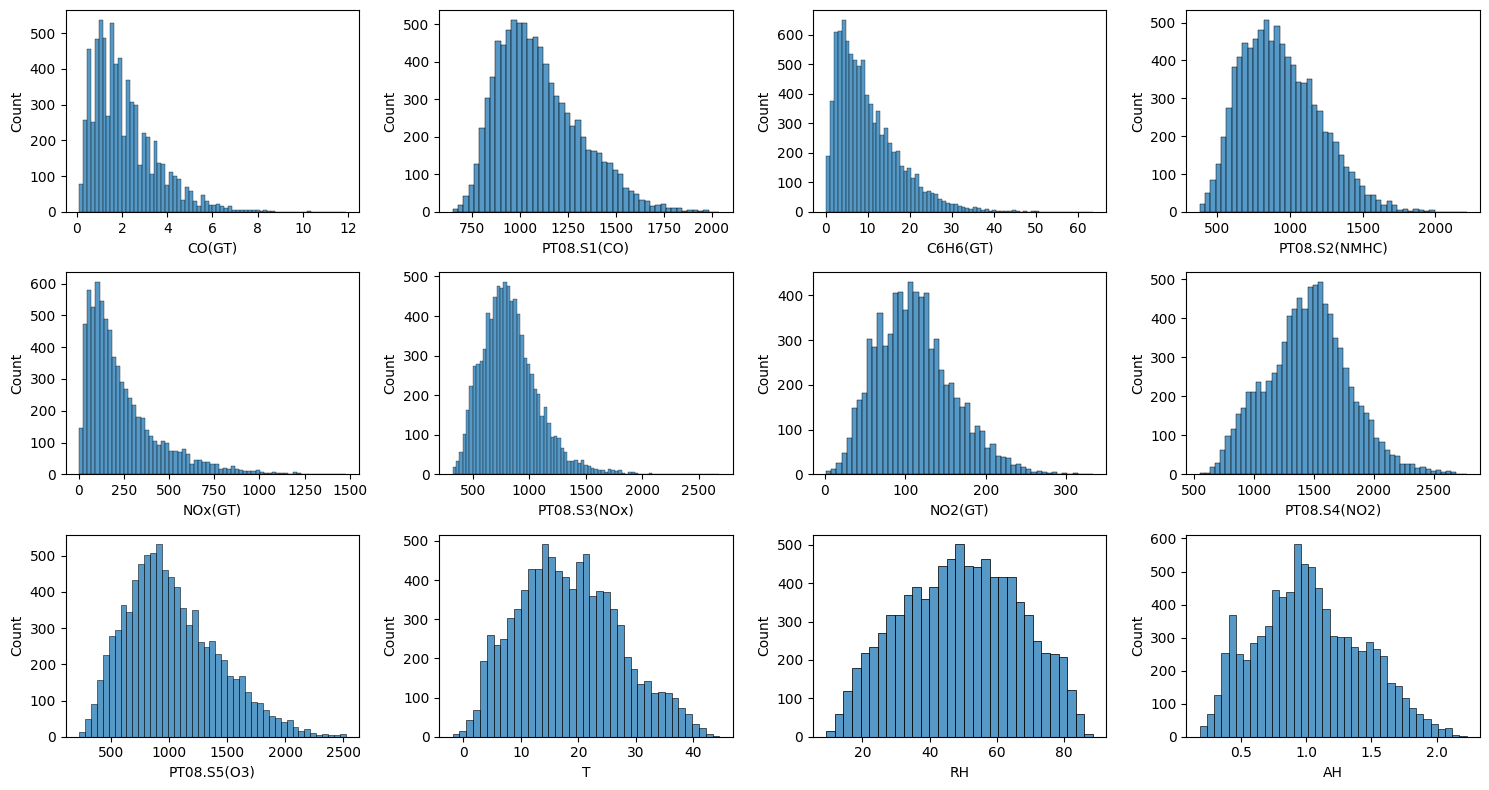

In [ ]:
NUMERIC_COLS = df.columns[:-1]
def plot_distributions(data:pd.DataFrame, cols:list, plot_type)->None:
  fig, ax = plt.subplots(3, 4, figsize=(15, 8))
  ax_flat = ax.flatten()
  for i, col in enumerate(cols):
      plot_type(data=data, x=col, ax=ax_flat[i])
  plt.tight_layout()
  plt.show()
plot_distributions(data=df, cols=NUMERIC_COLS, plot_type=sns.histplot)

In addition to histograms I also created boxplots, to better see presence of outliers and their number. Here I conclude, that distributions of features **T**, **RH** and **AH** are almost symmnetrical, as there are almost no outliers (according to IQR rule). All other variables have quite a lot outliers on the right side.

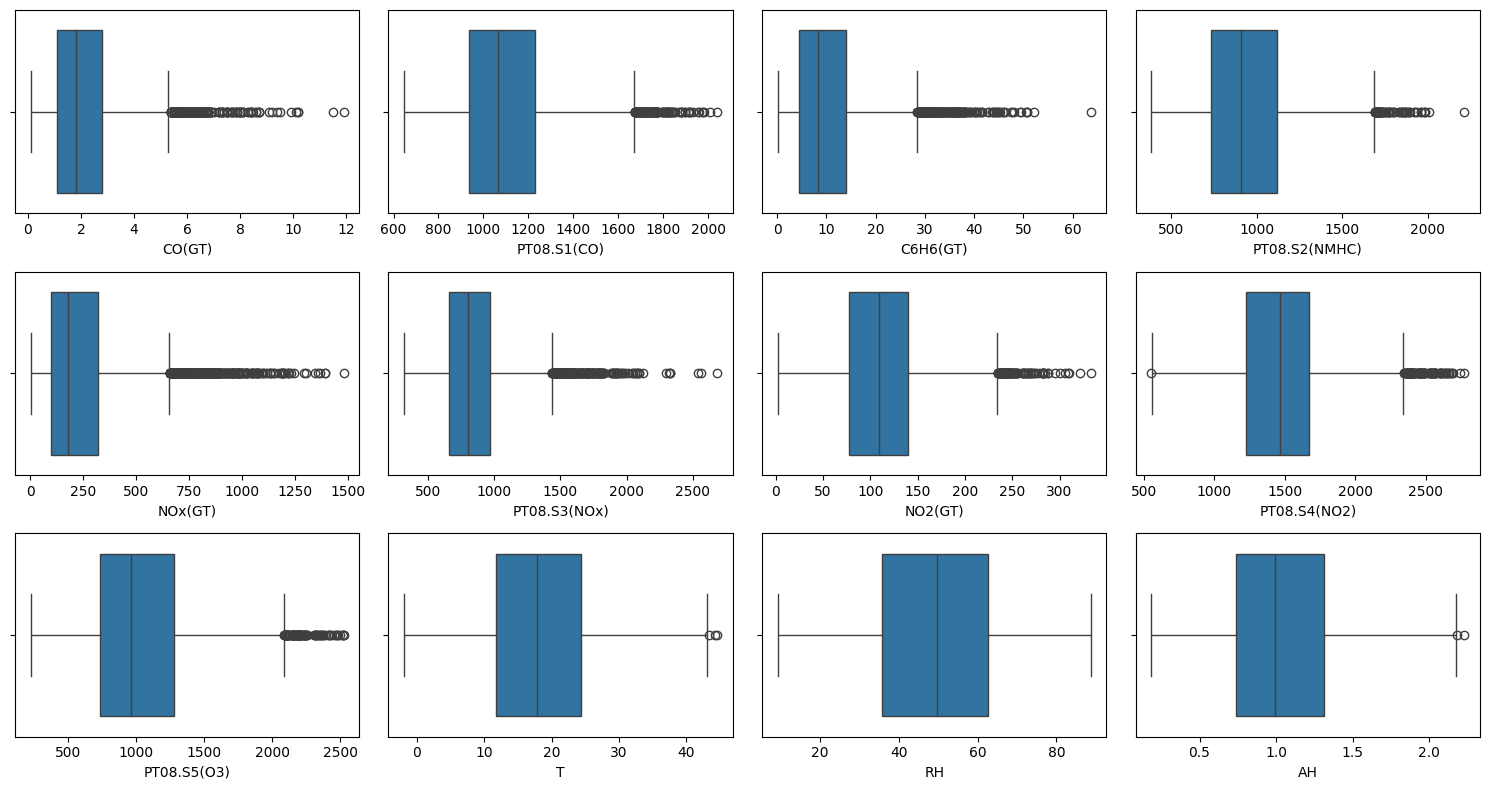

In [ ]:
plot_distributions(data=df, cols=NUMERIC_COLS, plot_type=sns.boxplot)

And here I want to add my thoughts about outliers in this dataset. I think, that here may be 2 main reasons for their presence:
1. Faults in sensors or other devices, which as a result show abnormal measurtments.
2. Really abnormal measurements indicating poor air quality. It is intuitive, that such results are quite rare comparing to measurments for "normal" air quality. However they can be a good representation of patterns in the data.

Personally, I assume, that most of anomalies correspond to the second point. Removing such observations may result in dataset without bad air quality measurments and lost important patterns in data. So here I decide not to remove outliers.



## 3.2 Multivariate Analysis

### 3.2.1 Target Variable vs Datetime

Here I tried to check whether **Datetime** variable has inpact on the target variable. In the plot below it is hard to find any patterns. So I will try another solution.

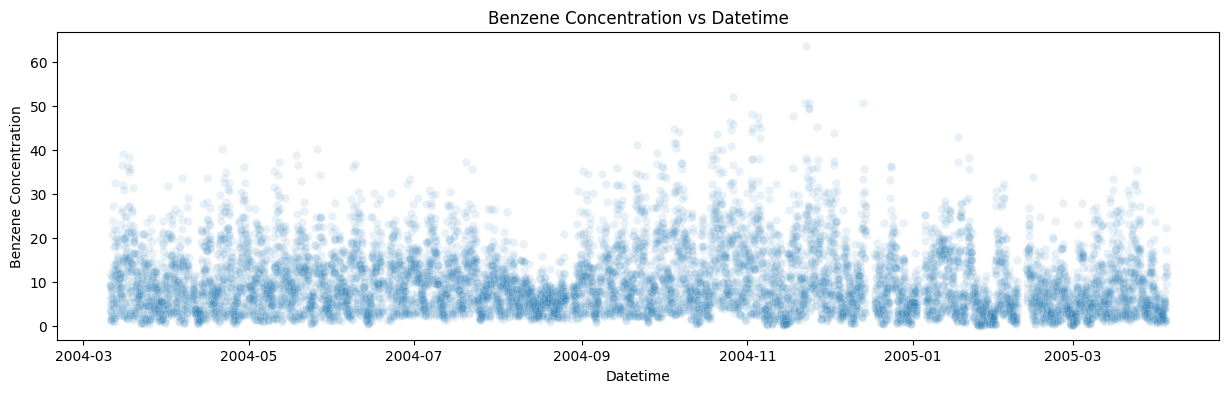

In [ ]:
plt.figure(figsize=(15,4))
sns.scatterplot(data=df, x='Datetime', y='C6H6(GT)', alpha=0.1)
plt.title('Benzene Concentration vs Datetime')
plt.xlabel('Datetime')
plt.ylabel('Benzene Concentration')
plt.show()

And below is the solution, that I found. Instead of looking at whole time period, I made plot of only one month (in fact it is even shorter period). And here we can see interesting pattern. There is for sure some periodicity in the data (plot looks like sinusoid).

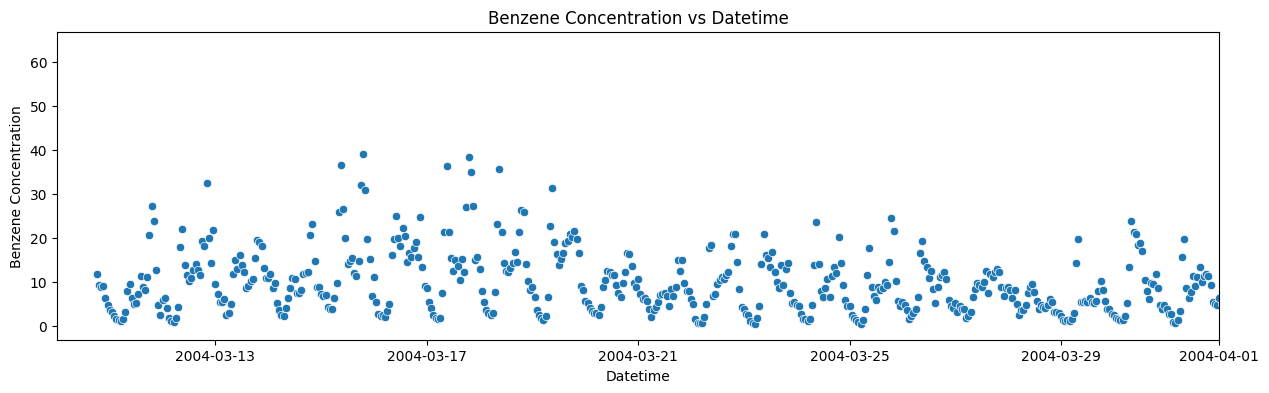

In [ ]:
plt.figure(figsize=(15,4))
sns.scatterplot(data=df, x='Datetime', y='C6H6(GT)')
plt.xlim(pd.Timestamp('2004-03-10'), pd.Timestamp('2004-04-01'))
plt.title('Benzene Concentration vs Datetime')
plt.xlabel('Datetime')
plt.ylabel('Benzene Concentration')
plt.show()

#### 3.2.1.1 Time of Day

And I think, that I found this pattern!

I grouped data by hour and calculated mean target variable. We see, that at night generally benzene concentration in air is lower with minimal results at 4-5 AM. At day measurements are generally higher with lokal peaks in the morning around 8:00 and in the evening around 18:00-19:00. It is intuitive, as at that time there is rush hour, and air quality should be poorer. Especially considering the fact, that measurements were collected near the road.

To sum up, time seems to have crucial role in benzene concentration results and it will be for sure considered as new variable.

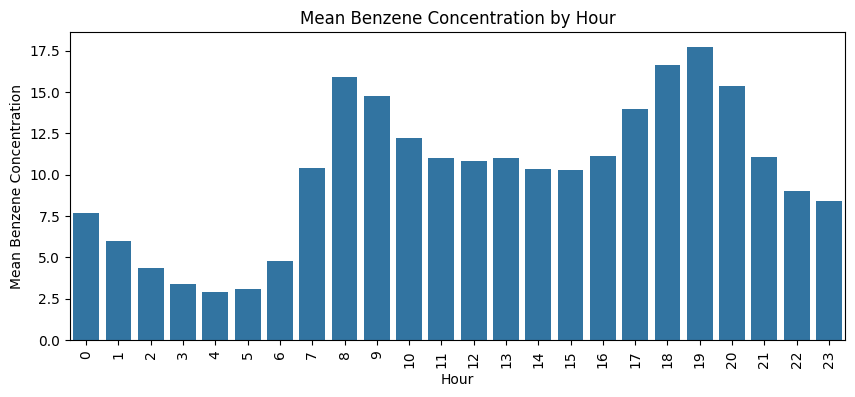

In [ ]:
hours = df['Datetime'].dt.hour
target_by_hour = df.groupby(hours).mean()['C6H6(GT)']
plt.figure(figsize=(10,4))
sns.barplot(x=target_by_hour.index, y=target_by_hour.values)
plt.xticks(rotation=90)
plt.title('Mean Benzene Concentration by Hour')
plt.xlabel('Hour')
plt.ylabel('Mean Benzene Concentration')
plt.show()

As time has impact on target variable, as I concluded before, it is important to include this factor to the dataset. I decided to create categorical feature **Time of Day**, which will have value **Day** if time is between 8:00 and 19:00 including, otherwise it will be **Night**. I decided to create only 2 classes instead of class for each distinct hour, as I dont want to significantly increase data dimensionality after using one hot encoding.

I created a boxplot to show relation between newly created feature and target variable. As we can see there is evident difference between Day and Night distributions. Values for Day are clearly higher with median at around 12 comparing to value around 5 for Night. After creating the plot I added new feature to the dataset.

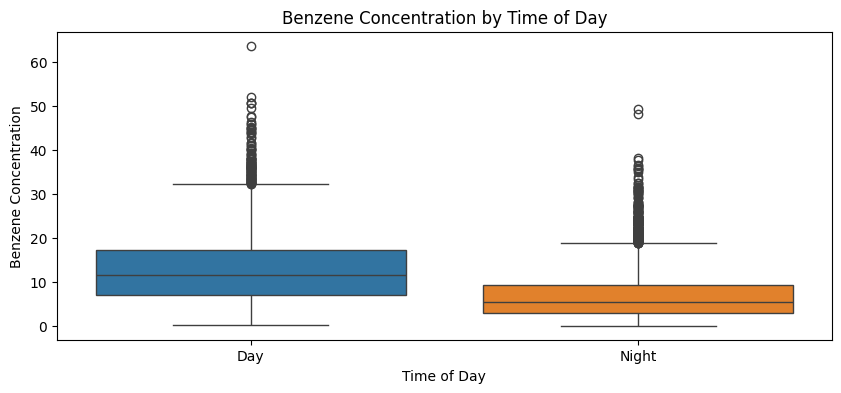

In [ ]:
time_of_day = np.where(hours.between(8, 19), 'Day', 'Night')
plt.figure(figsize=(10,4))
sns.boxplot(data=df, x=time_of_day, y='C6H6(GT)', hue=time_of_day)
plt.title('Benzene Concentration by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Benzene Concentration')
plt.show()

In [ ]:
df['Time_of_Day'] = time_of_day

#### 3.2.1.2 Day of Week

Nextly, I wanted to check whether day of week can be a good predictor. As we can see below, mean benzene concentration is on average lower at the weekend. In my opinion it is due to less number of cars during the weekend, as people dont need to drive to their place of work. My idea is here to create variable, which will represent whether observation was made at weekend or any working day.

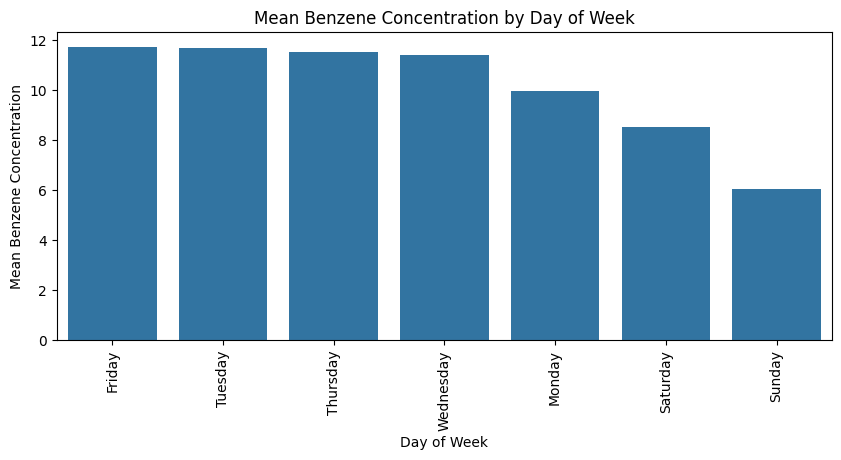

In [ ]:
weekdays = df['Datetime'].dt.day_name()
target_by_weekday = df.groupby(weekdays)['C6H6(GT)'].mean().sort_values(ascending=False)
plt.figure(figsize=(10,4))
sns.barplot(x=target_by_weekday.index, y=target_by_weekday.values)
plt.xticks(rotation=90)
plt.title('Mean Benzene Concentration by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Mean Benzene Concentration')
plt.show()

Below I created the variable, which I mentioned above, and prepared plot to show it's impact on target variable. Again we see, that at workday benzene concentration tends to be higher, so I conclude, that created variable is correlated with target variable and can be a good predictor. This feature will be added to the data frame.

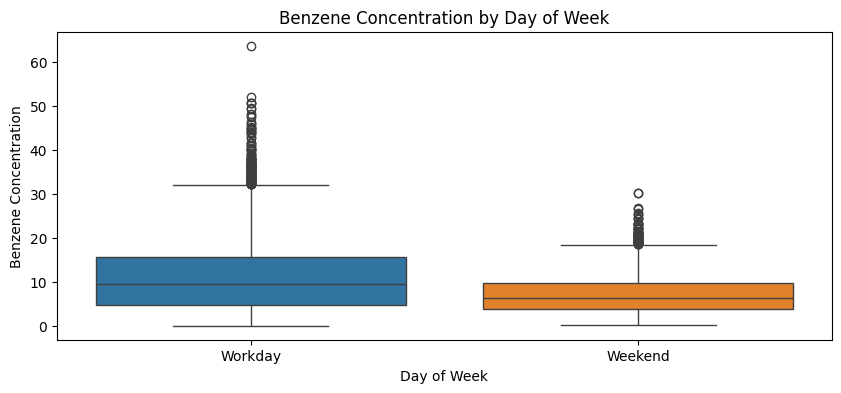

In [ ]:
weekend = np.where(weekdays.isin(['Saturday', 'Sunday']), 'Weekend', 'Workday')
plt.figure(figsize=(10,4))
sns.boxplot(data=df, x=weekend, y='C6H6(GT)', hue=weekend)
plt.title('Benzene Concentration by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Benzene Concentration')
plt.show()

In [ ]:
df['Weekend'] = weekend

#### 3.2.1.3 Season

Now I want to check whether month has any impact on target variable. I noticed, that there is higher benzene concentration in autumn months is higher than in other months. On the other side, winter measurments seem to be lower than other. I think, it is a good idea to check season's influence on target variable.

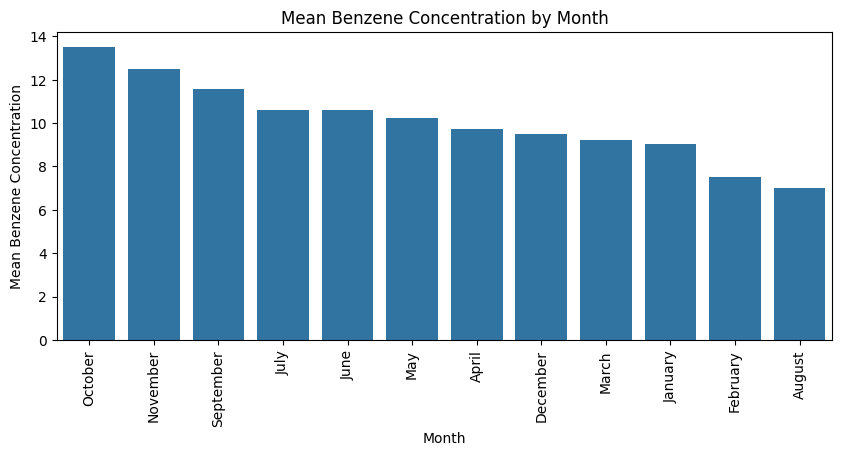

In [ ]:
months = df['Datetime'].dt.month_name()
target_by_month = df.groupby(months)['C6H6(GT)'].mean().sort_values(ascending=False)
plt.figure(figsize=(10,4))
sns.barplot(x=target_by_month.index, y=target_by_month.values)
plt.xticks(rotation=90)
plt.title('Mean Benzene Concentration by Month')
plt.xlabel('Month')
plt.ylabel('Mean Benzene Concentration')
plt.show()

In the plot below we see, that in autumn benzene concentration tends to be higher, however it is hard to see significant difference between other seasons. Newly created variable was added to the data.

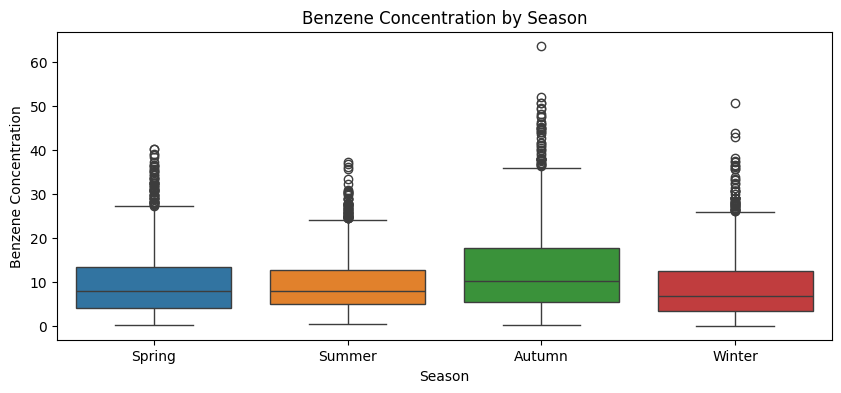

In [ ]:
def get_season(month):
    if month in ['December', 'January', 'February']:
      return 'Winter'
    elif month in ['March', 'April', 'May']:
      return 'Spring'
    elif month in ['June', 'July', 'August']:
      return 'Summer'
    else:
      return 'Autumn'
season = np.vectorize(get_season)(months)
plt.figure(figsize=(10,4))
sns.boxplot(data=df, x=season, y='C6H6(GT)', hue=season)
plt.title('Benzene Concentration by Season')
plt.xlabel('Season')
plt.ylabel('Benzene Concentration')
plt.show()

In [ ]:
df['Season'] = season

### 3.2.2 Numerical Variables

Now I want to see correlation between numerical features in the dataset. To do so I prepared correlation matrix presented as clustermap. This approach helps me to see better more correlated features, as they will be clustered together. I would like to begin from the left top corner.



1. There is a big red block, which signalise highly positively correlated variables. There a both hourly responses from sensors and concentration of chemical elements in the air, that are considered as polluting ones (there is also our target variable there). Those high correlations are quite intuitive, as more dirty air is, more concentration of polluting elements will be in the air and more alarm responses from sensors will be.
2. However one variable is highly negatively correlated with the ones mentioned above. It is **PT08.S3**, another count of responses from some sensor. My assumption is, that this specific sensor is working in different way. So for poor air quality it will remain silent, but if the air is clean, there will be plenty of responses.
3. There is another cluster of correlated features in the right bottom corner. It consists of 3 variables: **T**, **RH** and **AH**. From my search one of this variables can be presented as function of others, what explains their high correlation.
4. Another thing to notice, is unrealisticly high correlation between target and **PT08.S2**, what should be checked further.

As we can see, there are many highly correlated variables in the dataset. From one point of view, high correlation with target variable is a good news. From the other hand, it is a big problem, as that means a multicolinearity in future model if all variables will be included. So it is important to think about preventive measures, such as feature selection, regularization or dimensionality redution.




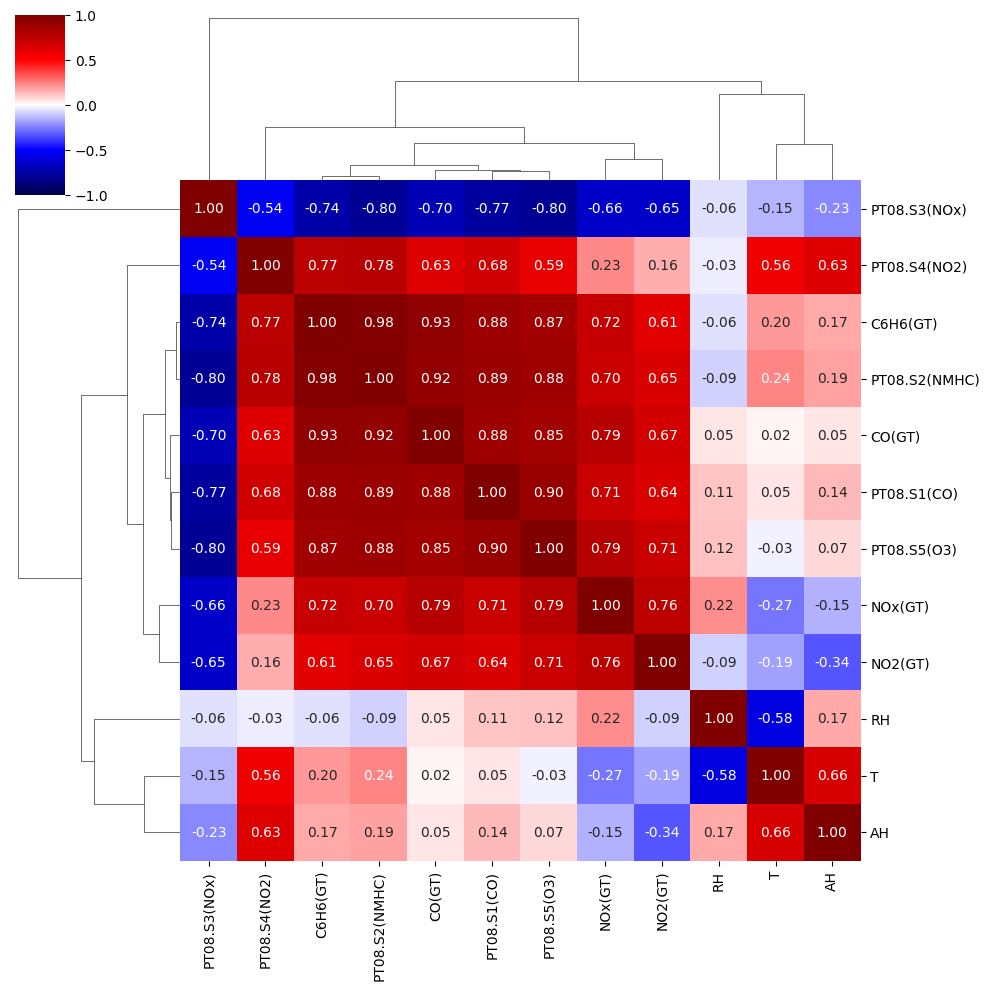

In [ ]:
sns.clustermap(df[NUMERIC_COLS].corr(), cmap='seismic', vmin=-1, vmax=1, annot=True, fmt='.2f')
plt.show()

To have better understanding of relations between numerical variables pairplot was created.

Quick note: plot is probably too messy and I probably should have used subset of features, however I wanted to have a wider overview.

Again we can see all correlations, that were presented in the clustermap, but now we also see whether they are linear or not. So majority of them is linear, however not all of them. Let's look closer at target variable. Here are some insights:
1. Majority of scatterplots shows linear relation between independent variables and target.
2. There is no visible correlation between **T**, **RH** and **AH** and target.
3. Relation between **PT08.S3** and target is not linear, what suggests that using polynomial regression to catch that pattern can be good idea.
4. Suspicious relation between target and **PT08.S2** now looks even more suspicious, as there is no visible noise and clear relation. I think, there may be problem od data leakage, if this independent variable will be added to the model. I unsuccessfully tried to make search and find any proof of that. However, I think it is safer to remove this suspicious variable from data to have more reliable model.

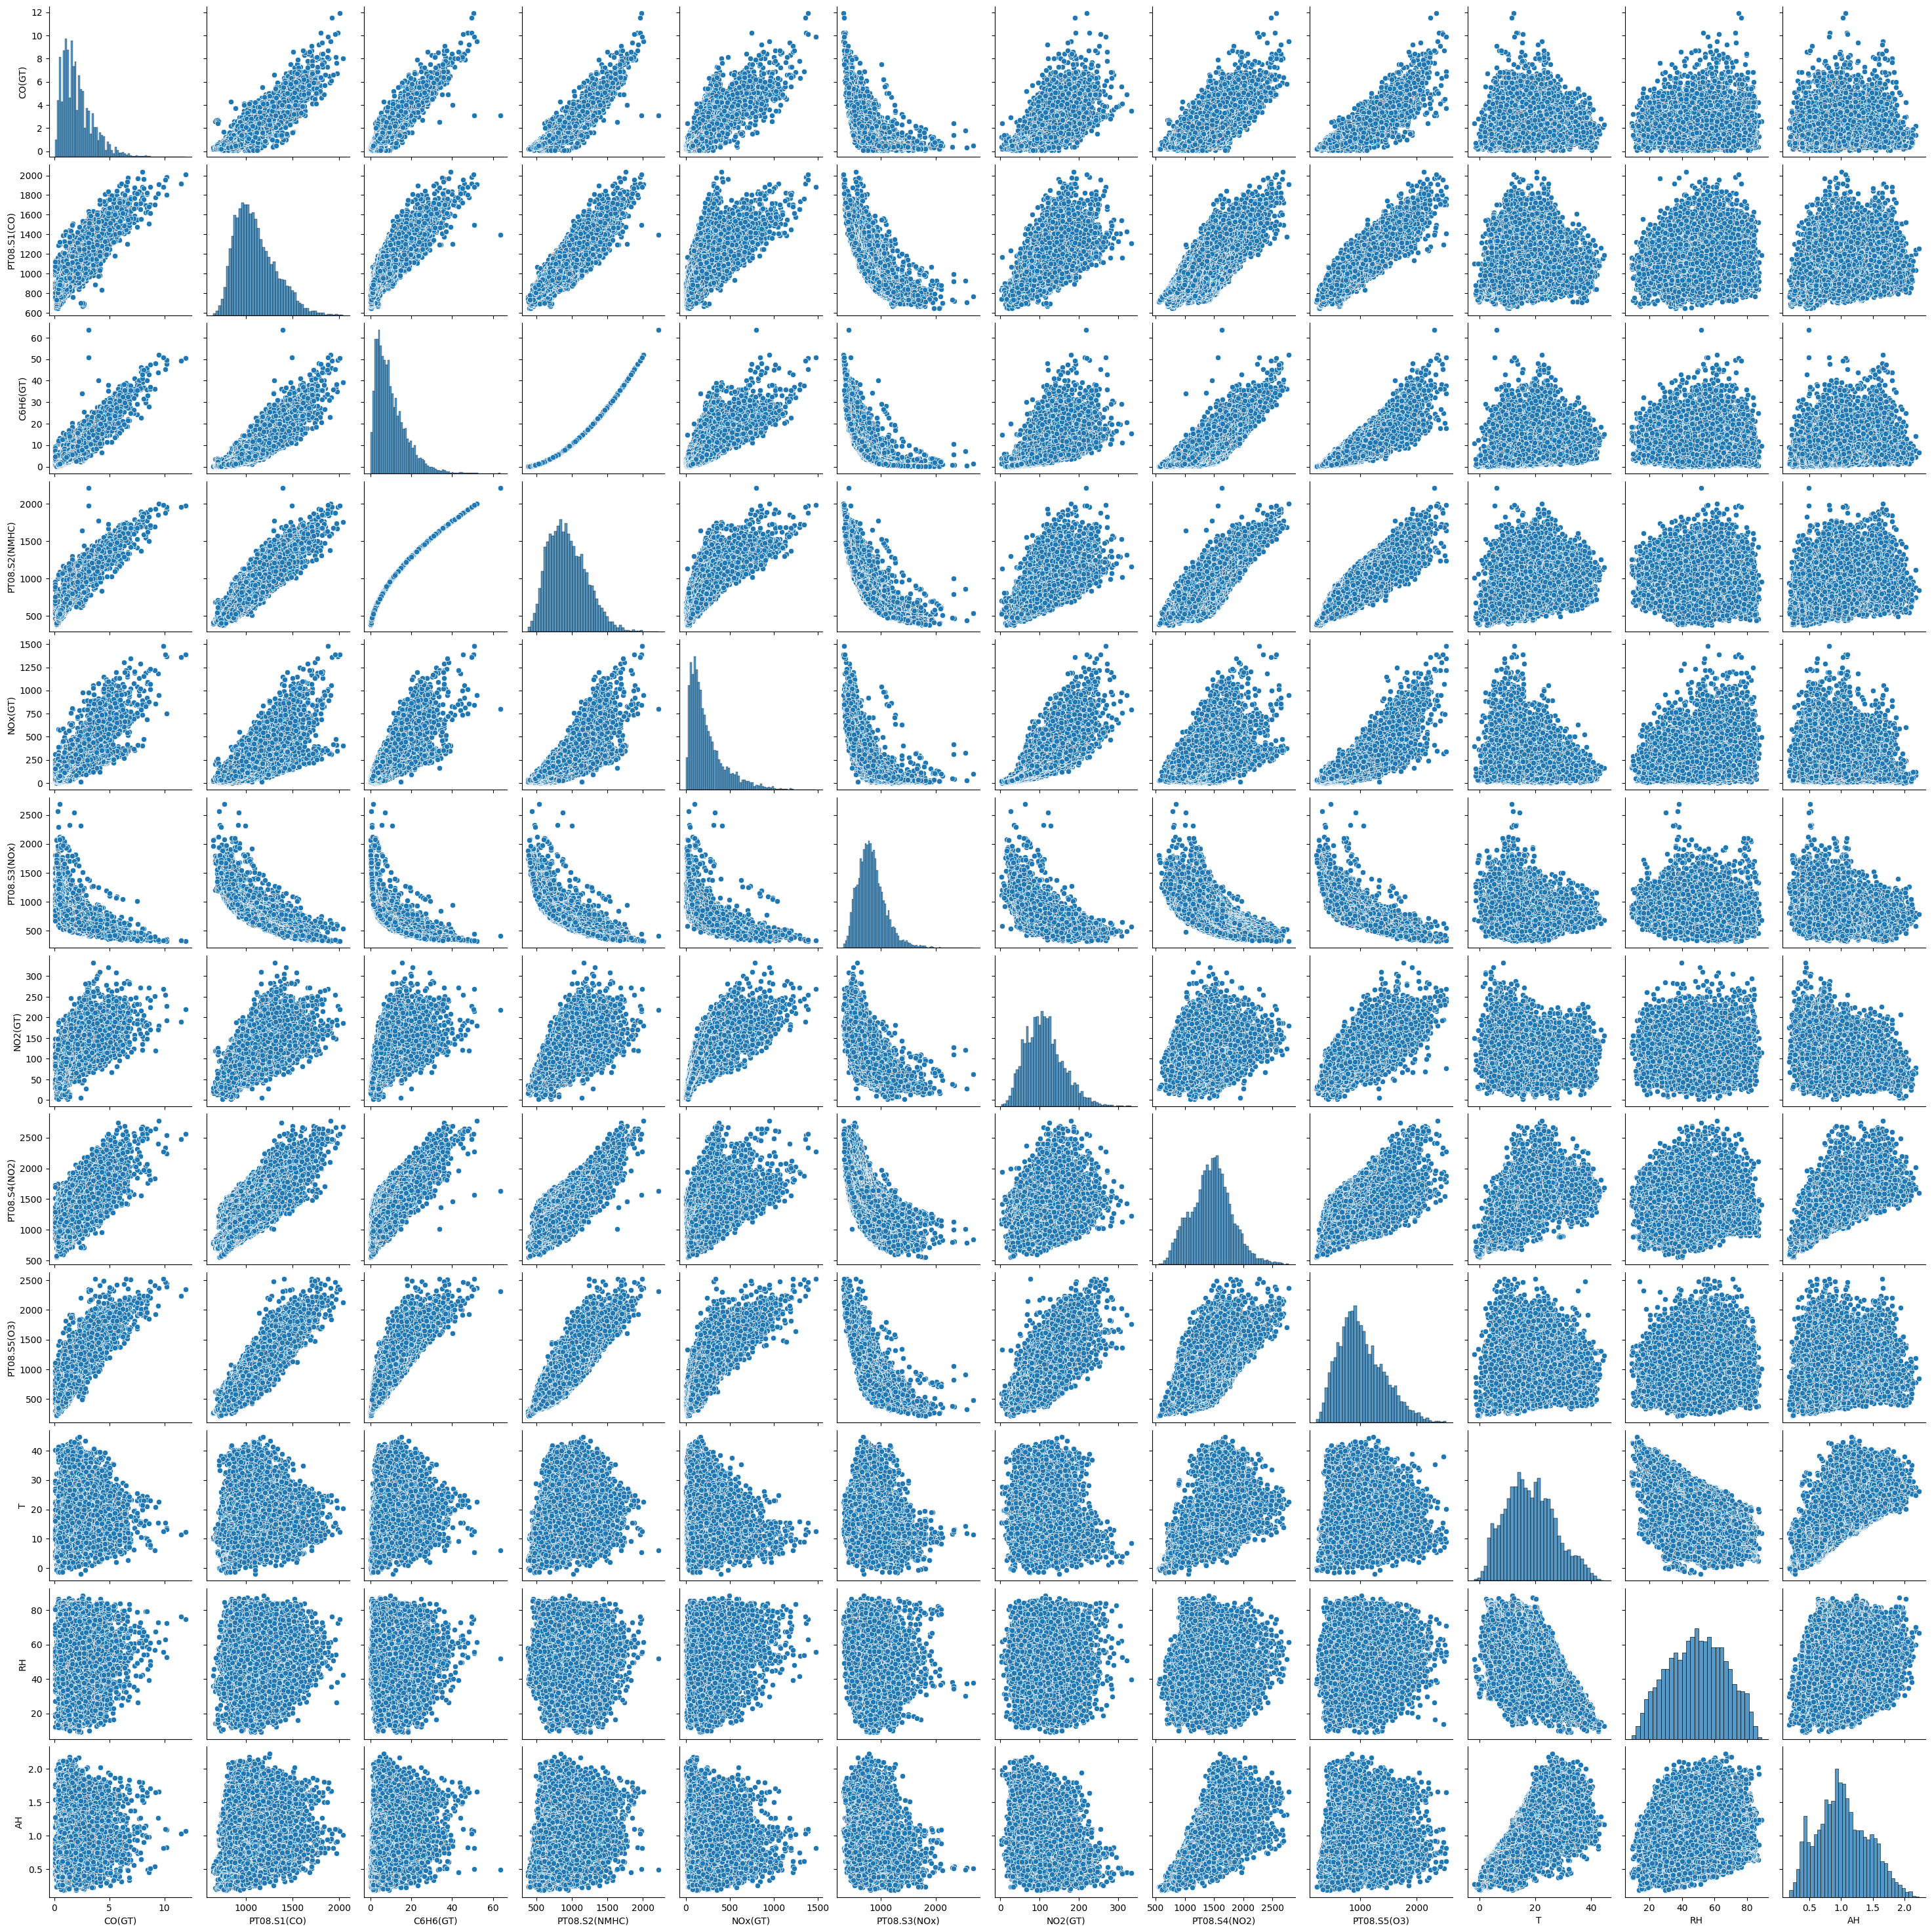

In [ ]:
sns.pairplot(data=df[NUMERIC_COLS])
plt.show()

In [ ]:
df = df.drop('PT08.S2(NMHC)', axis=1)

# 4. Data Preparation

In this part I will prepare data before adding it to the model.

Firstly, target variable and predictors should be separated. Additionally, column **Datetime** should be removed, as all useful information from it is already stored in other variables.

In [ ]:
X = df.drop(['C6H6(GT)', 'Datetime'], axis=1)
y = df['C6H6(GT)']

Nextly, there was created function get_pipe(), which returns data transformation pipeline for data frame with predictors. Now I will briefly explain, how it works.

So, firstly there is created sub-pipeline for numerical variables, which are separated from the categorical ones. Initial step is imputing. As it was already noticed, there are still some null values in the dataset in some numerical variables. I chose Iterative Imputer for this task. My idea is, that numerical variables in our dataset are highly correlated with each other, so their relations could be useful to impute missing values. That is why I decided to use multivariate imputation instead of something simplier, like mean or median. Nextly, I added possibility to create interactions and polynomial features of selected polynomial degree. So when I will need to perform polynomial regression, I will again use this function with adjusted degree parameter. In the end all numerical features are scaled. For this purpose I decided to use Robust Scaler. As I mentioned before, there are plenty of outliers in the dataset, so I chose less outlier-sensitive scaler, which relies on more robust median and IQR, instead of mean and standard deviation.

Separately there are transformed categorical features. There is only one designed step for them. They are encoded with One Hot Encoder, as all of them are nominal, and with first column dropped to avoid dummy variable trap.

After that all numerical and categorical features are combined together again.

Finally, there is performed forward stepwise selection to choose step by step only features, which can improve model performance. I see few pros of this step. Firstly, reduced dimensionality, what reduces time needed to train model, what could be usuful in case of high-degree polynomials created. Secondly, choosing less features may prevent overfitting. And lastly it is a good way to deal with multicollinearity, which is highly expected without feature selection, as we saw before.

In [ ]:
CONTINUOUS_VARIABLES = X.select_dtypes(float).columns
CATEGORICAL_VARIABLES = X.select_dtypes(object).columns
def get_pipe(poly_degree:int=1)->Pipeline:
  num_pipe = Pipeline([
        ("imputer", IterativeImputer()),
        ("poly", PolynomialFeatures(degree=poly_degree, include_bias=False)),
        ("scaler", RobustScaler())
    ])
  cat_pipe =  Pipeline([
      ("one_hot", OneHotEncoder(drop='first', sparse_output=False))
    ])
  col_transformer = ColumnTransformer([
      ("num", num_pipe, CONTINUOUS_VARIABLES),
      ("cat", cat_pipe, CATEGORICAL_VARIABLES)
    ])
  feature_selector = SequentialFeatureSelector(
      estimator=LinearRegression(),
      tol=0.001
    )
  pipe = Pipeline([
      ("col_transformer", col_transformer),
      ("feature_selector", feature_selector)
    ])
  pipe.set_output(transform="pandas")
  return pipe

Now it is time for splitting data into training and test set. My idea is here to firstly split data into training and test set. Training set will be used for training models and Grid Search Cross-Validation for choosing best hyperparameters. Test set will be used only in the end, to make final evaluation of the model. As data is time series, safe approach is to split it chronologically. I chose to divide data in proportion of 80%/20% for training/test data.

In [ ]:
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

Here I will use get_pipe() function to transform X_train and X_test data frames with predictors.

In [ ]:
pipe_lm = get_pipe()
X_train_lm = pipe_lm.fit_transform(X_train, y_train)
X_test_lm = pipe_lm.transform(X_test)

Now data is ready for training models.

# 5. Models

To train and test model, and after that immediately get the report, I designed function get_model_report(). User need to pass model name, data and hyperparameter grid (optional). After that function will use Grid Search Cross-Validation to find best parameters and report them. Nextly, some metrics will be measured both on train and test data to check whether there is overfitting. Test metrics alone will be used to evaluate model performance on unseen data. Metrics include R2, to check how well model is fitted to data, MAE and RMSE to evaluate model error. Nextly model coefficients will be reported. As all features in the model passed forward selection, they may be considered as significant ones. In the end 2 plots will be constructed to analyse model's residuals.

In [ ]:
tscv = TimeSeriesSplit(n_splits=3)
def get_model_report(model, X_train:pd.DataFrame=X_train_lm, y_train:pd.Series=y_train,
                     X_test:pd.DataFrame=X_test_lm, y_test:pd.Series=y_test,
                     param_grid:dict={}):
  grid = GridSearchCV(model, param_grid, cv=tscv)
  grid.fit(X_train, y_train)
  y_train_preds = grid.predict(X_train)
  y_test_preds = grid.predict(X_test)
  print(f'Best hyperparameters: {grid.best_params_}')
  print(f'Train R2 score: {r2_score(y_train, y_train_preds)}')
  print(f'Train MAE: {mean_absolute_error(y_train, y_train_preds)}')
  print(f'Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_preds))}')
  print(f'Test R2 score: {r2_score(y_test, y_test_preds)}')
  print(f'Test MAE: {mean_absolute_error(y_test, y_test_preds)}')
  print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, y_test_preds))}')
  coefs = pd.Series(grid.best_estimator_.coef_, index=X_train.columns)
  print(f'Model coefficients:')
  print(coefs)
  fig, ax = plt.subplots(1, 2, figsize=(12,4))
  plt.title('Residual Analysis')
  sns.scatterplot(x=y_test, y=y_test_preds, ax=ax[0])
  ax[0].axline((0,0), slope=1, color='r', linestyle='--')
  ax[0].set_title('Actual vs Predicted Values')
  ax[0].set_xlabel('Actual Value')
  ax[0].set_ylabel('Predicted Value')
  sns.scatterplot(x=y_test, y=y_test-y_test_preds, ax=ax[1])
  ax[1].axhline(y=0, color='r', linestyle='--')
  ax[1].set_title('Residual Plot')
  ax[1].set_xlabel('C6H6(GT)')
  ax[1].set_ylabel('Residuals')
  plt.show()

## 5.1 Baseline Linear Regression

Firstly, baseline linear regression model was created. Below are presented the results. The model performance can be for sure considered as really good. Difference between train and test metrics are not that different, so, personally, I cant conclude, that model is overfitted. We can see, that for test data almost 90% of variance is explained by the model. Additionally error metrics are also not bad and error is not high. We can understand it by comparing those values with descriptive statisctics obtained before. Mean of target variable in whole dataset was equal to *10.083105* and standard deviation was equal to *7.44982*. In my opinion RMSE of only around 2 is a good result for distribution with such high variance.

I dont see on the plots any strange patterns, a model's residuals seem to be normally distributed, what satisfies some assumptions of linear regression and gives possibility to analyse model coefficients.

When it comes to coefficients, we firstly see, that only 6 features are finally in the model (**CO(GT)**, **NOx(GT)**, **PT08.S4(NO2)**, **PT08.S5(O3)**, **RH**, **Weekend_Workday**). All of them, except **RH** show positive correlation with target variable. It seems, that the strongest influence on target variable show variables **CO(GT)** and **PT08.S4(NO2)**, which stands for scaled hourly averaged concentration of CO.

One thing, that I noticed from the plot is fact, that model may predict target variable to be negative, however it is unrealistic. So potentially GLM, which will adjust distribution of predicted variable may resolve this problem.

Best hyperparameters: {}
Train R2 score: 0.94622538246613
Train MAE: 1.1982574334820026
Train RMSE: 1.7540027987801652
Test R2 score: 0.8982869358861371
Test MAE: 1.5983312885189251
Test RMSE: 2.077738123942537
Model coefficients:
num__CO(GT)             3.646489
num__NOx(GT)            1.634846
num__PT08.S4(NO2)       3.177268
num__PT08.S5(O3)        1.554921
num__RH                -1.428741
cat__Weekend_Workday    0.629481
dtype: float64


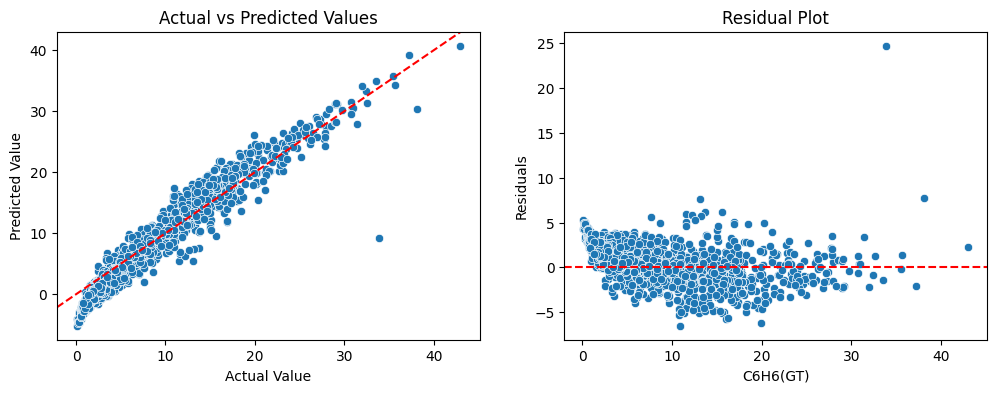

In [ ]:
get_model_report(LinearRegression())

## 5.2 Lasso Regression

Now I will try to implement regularization techniques and the first one will be Lasso. What is interesting, this model shows almost identical results as the baseline one. The differences between all metrics and feature coefficients are hard to see. So all conclusions from previous model are applied here.

One thing to notice, that best alpha value for Lasso is equal to 0.0001 after Grid Search, what means, that there was only weak regularization. That explains, why results are similar. Results of hyperparameter tuning suggest that here no regularization is needed. Let's see how Ridge regression will look like.

Best hyperparameters: {'alpha': np.float64(0.0001)}
Train R2 score: 0.9462253807622845
Train MAE: 1.1982441933141925
Train RMSE: 1.7540028265679017
Test R2 score: 0.8982989502159627
Test MAE: 1.5982194820289983
Test RMSE: 2.077615409281844
Model coefficients:
num__CO(GT)             3.646818
num__NOx(GT)            1.634588
num__PT08.S4(NO2)       3.177109
num__PT08.S5(O3)        1.554811
num__RH                -1.428419
cat__Weekend_Workday    0.629050
dtype: float64


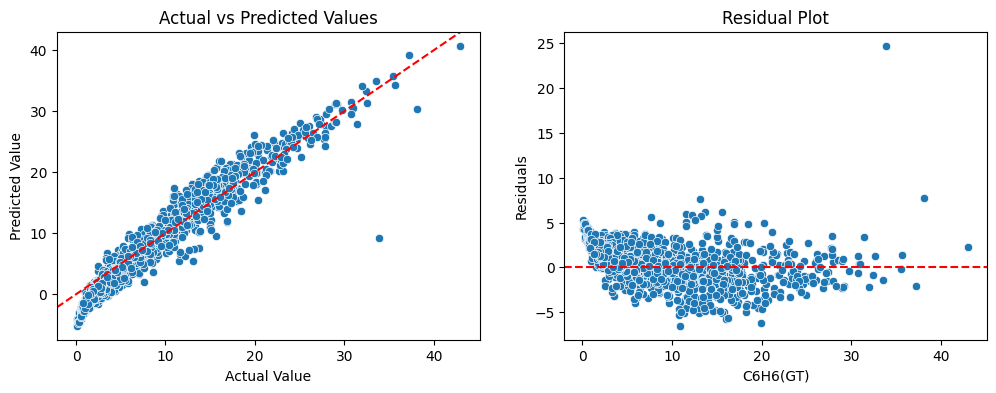

In [ ]:
alpha = np.linspace(0.0001, 100, 200)
get_model_report(Lasso(), param_grid={'alpha': alpha})

## 5.3 Ridge Regression

Again results are almost identical, so again conclusions are the same. However, results are slightly better for test set. It is a really small change, but I must conclude, that now results are better.

Probable reason for such improvement is selected regularization parameter alpha=100.

Best hyperparameters: {'alpha': np.float64(100.0)}
Train R2 score: 0.9461113652356776
Train MAE: 1.1978418104518438
Train RMSE: 1.755861302437384
Test R2 score: 0.9016662851420336
Test MAE: 1.569088213006348
Test RMSE: 2.042930832294453
Model coefficients:
num__CO(GT)             3.476984
num__NOx(GT)            1.664262
num__PT08.S4(NO2)       3.159227
num__PT08.S5(O3)        1.661887
num__RH                -1.401190
cat__Weekend_Workday    0.611675
dtype: float64


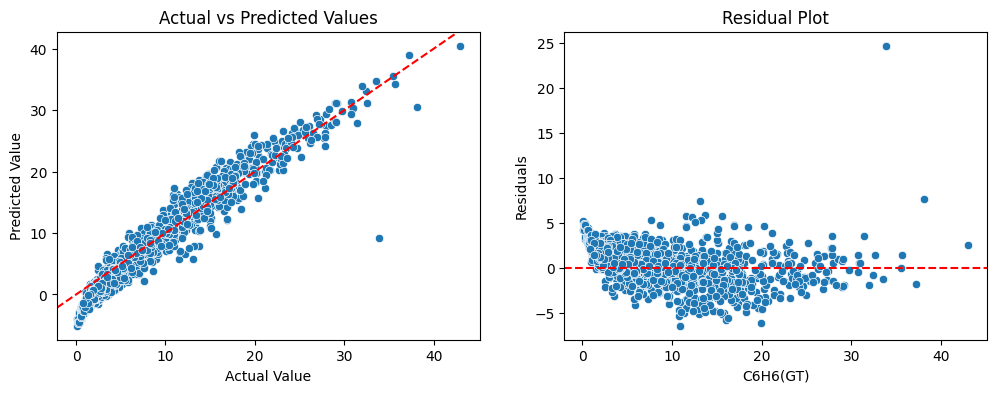

In [ ]:
get_model_report(Ridge(), param_grid={'alpha': alpha})

## 5.4 Elastic Net

Here we will end experiments with regularization by applying Elastic Net Regression Model.

Again we see similar results, but worse than in case of Ridge Regression.

Here best estimator has alpha value = 0.0001 (again very small, like for Lasso) and l1_ratio = 0.0001, what means, that there was applied mostly Ridge regularization and just a little the Lasso one.

Best hyperparameters: {'alpha': np.float64(0.0001), 'l1_ratio': np.float64(0.0001)}
Train R2 score: 0.9462253754032268
Train MAE: 1.1982485593040602
Train RMSE: 1.7540029139678885
Test R2 score: 0.898311517287114
Test MAE: 1.59812594277843
Test RMSE: 2.077487041151134
Model coefficients:
num__CO(GT)             3.645008
num__NOx(GT)            1.635132
num__PT08.S4(NO2)       3.177195
num__PT08.S5(O3)        1.555856
num__RH                -1.428569
cat__Weekend_Workday    0.629338
dtype: float64


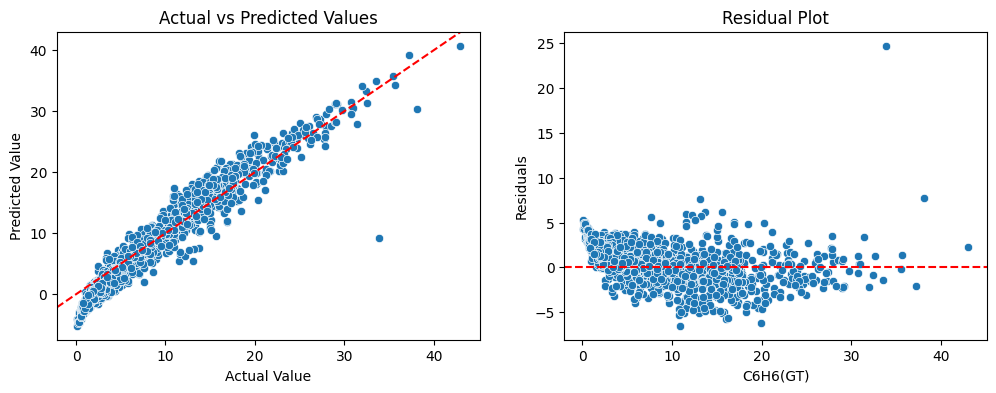

In [ ]:
l1_ratio = np.linspace(0.0001, 1, 20)
get_model_report(ElasticNet(), param_grid={'alpha': alpha, 'l1_ratio':l1_ratio})

## 5.5 Polynomial Regression

Now Polynomial Regression will be performed. Firstly, I need to create new variables: polynomial features and interactions. Again I will use already created get_pipe() function.

In [ ]:
pipe_poly = get_pipe(poly_degree=2)
X_train_poly = pipe_poly.fit_transform(X_train, y_train)
X_test_poly = pipe_poly.transform(X_test)

When new features are created, it is time to train model.

Now we can see some changes. Train metrices improved just slightly, but there is definitly significant improvement in test metrics. Now, model explains above 95% of target variable variance (R2), error metrics MAE and RMSE also decreased to around *0.99* and *1.43* accordingly, what means, that new model is even more precise than the previous ones.

Variables included in the model also changed. Only **NOx(GT)** and **PT08.S5(O3)** are here and in previous models. Other variables are either interactions or polynomial feature. During EDA I noticed, that relation between target variable and **PT08.S3** was non-linear and that it should be considered in Polynomial Regression. Now squared **PT08.S3** is added to the model, what confirms pevious assumption. There are 2 variables, that have significantly higher coefficients than other ones: interaction between **CO(GT)** and **PT08.S4(NO2)** with strong positive impact on target variable, and interaction between **CO(GT)** and **PT08.S1(CO)** with strong negative impact on target variable. All features, but interactions between **CO(GT)** and **PT08.S1(CO)**, **NOx(GT)** and **T**, **PT08.S3(NOx)** and **RH**, have positive impact on dependent variable.

Residual plots again dont show any suspicious pattern and suggest, that residuals are normally distributed.

Best hyperparameters: {}
Train R2 score: 0.9595129473933726
Train MAE: 1.0207748198965614
Train RMSE: 1.5219475922159609
Test R2 score: 0.9518265088151764
Test MAE: 0.9898958958340174
Test RMSE: 1.429902746756162
Model coefficients:
num__NOx(GT)                     2.115598
num__PT08.S5(O3)                 1.975477
num__CO(GT) PT08.S1(CO)         -5.628327
num__CO(GT) PT08.S4(NO2)         8.317254
num__PT08.S1(CO) PT08.S4(NO2)    2.306250
num__NOx(GT) T                  -0.223382
num__PT08.S3(NOx)^2              0.595467
num__PT08.S3(NOx) RH            -1.740817
dtype: float64


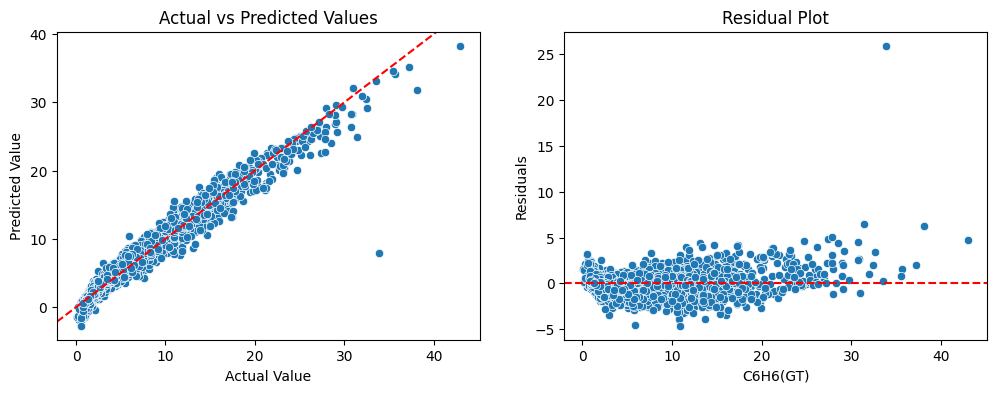

In [ ]:
get_model_report(LinearRegression(), X_train=X_train_poly, X_test=X_test_poly)

## 5.6 GLM

As it was noticed before, models above predicted many negative values. That is not possible and realistic for benzene concentration. To address this issue, I decided to use Generalized Linear Model. I chose GLM with a Gamma distribution and the ‘log’ link function. This solution will return only positive predictions and can deal with right-skewed target's distribution. That nicely matches with the benzene concentration distribution discovered during the EDA proccess.

As we can see below, now all metrics are worse than in previous models both for train and test sets. What is interesting, metrics are better for test data. Model explains around 87% of variance of unseen data and has RMSE equal to 2.37. That are definitely not bad results, but for sure worse than before.

The strength of this model is improved interpretability of predictions, as we can see below, they are all bigger than 0.

Residuals again look like normally distributed. Thing to notice: model systematically overestimates actual values that are close to 0. Such predictions are really closely clustered with little noise in residuals and noise is growing with growth of target variable. Potentially that suggests occurence of heteroscedasticity.

Best hyperparameters: {}
Train R2 score: 0.7919635994233621
Train MAE: 2.5464533831596228
Train RMSE: 3.449937937640823
Test R2 score: 0.8680713048846003
Test MAE: 1.9299537101321735
Test RMSE: 2.366312365800094
Model coefficients:
num__CO(GT)             0.165216
num__NOx(GT)            0.123205
num__PT08.S4(NO2)       0.167925
num__PT08.S5(O3)        0.150333
num__RH                -0.059008
cat__Weekend_Workday    0.024300
dtype: float64


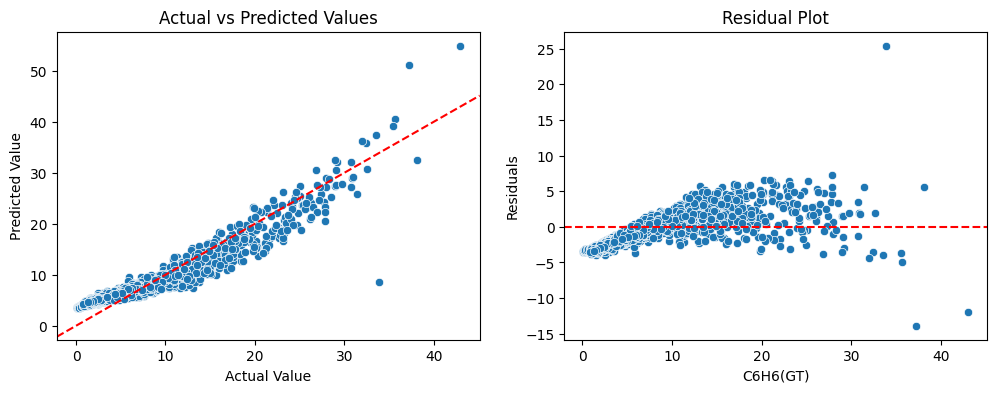

In [ ]:
get_model_report(GammaRegressor())

# 6. Conclusion

To conclude, baseline model and regularization ones showed similar results, with Ridge Regression being slightly better. However, Polynomial Regression with degree 2 outperformed all of them.

GLM showed the poorest results in terms of performance, however it is the only model with all predictions that make sense and could be interpreted.

So here choice between models is a trade-off between model performance and predictions interpretability.